# Temperature Regression + Kriging (Combined SAT + Street-View)

Joint PCA across all satellite and street-view predictors:
NDVI, NDBI, impervious, road_density, GVI, facade area, car count, sky ratio, road ratio.
The first two combined PCs feed a ridge regression; residuals are ordinary-kriged.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'spatial' / 'grid_rectangles.geojson').exists() and (candidate / 'src').exists():
            return candidate
    raise FileNotFoundError('Could not find project root.')


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / 'data'

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [10]:
# ── Load satellite layers ─────────────────────────────────────────────────
LAYER_DIR = DATA_DIR / 'kriging_satellite' / 'layers'
SV_DIR    = DATA_DIR / 'kriging_street_view'

sat_layer_paths = {
    'ndvi':         LAYER_DIR / 'ndvi_grid.geojson',
    'ndbi':         LAYER_DIR / 'ndbi_grid.geojson',
    'impervious':   LAYER_DIR / 'nlcd_impervious_grid.geojson',
    'road_density': LAYER_DIR / 'road_density_grid.geojson',
}
sv_layer_paths = {
    'gvi':        SV_DIR / 'grid_aggregated_gvi.geojson',
    'facades':    SV_DIR / 'grid_aggregated_facade_area.geojson',
    'cars':       SV_DIR / 'grid_aggregated_n_cars.geojson',
    'sky_ratio':  SV_DIR / 'grid_aggregated_sky_ratio.geojson',
    'road_ratio': SV_DIR / 'grid_aggregated_road_ratio.geojson',
}

missing = [k for k, p in {**sat_layer_paths, **sv_layer_paths}.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f'Missing layers: {missing}')

sat_gdfs = {name: gpd.read_file(path) for name, path in sat_layer_paths.items()}
sv_gdfs  = {name: gpd.read_file(path) for name, path in sv_layer_paths.items()}
print('SAT layers loaded:', list(sat_gdfs))
print('SV  layers loaded:', list(sv_gdfs))

SAT layers loaded: ['ndvi', 'ndbi', 'impervious', 'road_density']
SV  layers loaded: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


In [11]:
# ── Load sensor temperatures ──────────────────────────────────────────────
SENSORS_DIR = DATA_DIR / 'sensors'
sensor_csvs = {
    'Boston Carter Field':               SENSORS_DIR / 'boston_carter_field'         / 'boston_carter_field.csv',
    'Boston Gainsborough Parking Garage': SENSORS_DIR / 'boston_gainsborough_parking' / 'boston_gainsborough_parking.csv',
    'Boston Robinson Hall':              SENSORS_DIR / 'boston_robinson_hall'         / 'boston_robinson_hall.csv',
    'Boston West Village B':             SENSORS_DIR / 'boston_west_village_b'        / 'boston_west_village_b.csv',
    'Boston World Series Way':           SENSORS_DIR / 'boston_world_series_way'      / 'boston_world_series_way.csv',
}

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}
aligned_df, _ = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name='temperature',
    time_column='timestamp',
    sampling_interval='1min',
    timestamp_tolerance='15min',
)
sensor_temps = aligned_df.between_time('15:00', '16:00').mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / 'spatial' / 'sensor_locations.json')
sensor_names = list(sensor_csvs.keys())
sensor_locations = sensor_locations[sensor_locations['sensor_name'].isin(sensor_names)]
sensor_locations = sensor_locations.set_index('sensor_name').loc[sensor_names].reset_index()
sensor_locations['temperature'] = sensor_temps.reindex(sensor_names).values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations['longitude'], sensor_locations['latitude']),
    crs='EPSG:4326',
)
print(f'Sensors loaded: {len(gdf_sensors)}')
gdf_sensors[['sensor_name', 'temperature', 'geometry']]

Sensors loaded: 5


,sensor_name,temperature,geometry
0,Boston Carter Field,26.214514,POINT (-71.08435 42.33925)
1,Boston Gainsborough Parking Garage,28.377312,POINT (-71.08508 42.34039)
2,Boston Robinson Hall,28.198644,POINT (-71.08652 42.33919)
3,Boston West Village B,22.676928,POINT (-71.09238 42.33765)
4,Boston World Series Way,24.120776,POINT (-71.0899 42.33874)


In [12]:
# ── Build combined grid with all SAT + SV predictors ─────────────────────
def _ensure_grid_id(gdf):
    if 'grid_id' in gdf.columns: return gdf.copy()
    if 'id'      in gdf.columns: return gdf.copy().rename(columns={'id': 'grid_id'})
    return gdf.reset_index(drop=False).rename(columns={'index': 'grid_id'})

def _pick_col(gdf, candidates):
    for c in candidates:
        if c in gdf.columns: return c
    raise ValueError(f'None of {candidates} found in {list(gdf.columns)}')

# SAT feature column specs
sat_specs = [
    ('ndvi',         ['ndvi', 'ndvi_mean', 'ndvi_median']),
    ('ndbi',         ['ndbi', 'ndbi_mean', 'ndbi_median']),
    ('impervious',   ['impervious', 'nlcd_impervious', 'impervious_surface']),
    ('road_density', ['road_density_km_km2', 'road_density']),
]
# SV feature column specs
sv_specs = [
    ('gvi',        ['gvi_mean', 'gvi']),
    ('facades',    ['facade_area_mean', 'facade_area', 'facades']),
    ('cars',       ['n_cars_mean', 'n_cars', 'cars']),
    ('sky_ratio',  ['sky_ratio_mean', 'sky_ratio']),
    ('road_ratio', ['road_ratio_mean', 'road_ratio']),
]

base = _ensure_grid_id(sat_gdfs['ndvi'])
base_crs = base.crs
grid_features = base[['grid_id', 'geometry']].copy()

for out_name, candidates in sat_specs:
    layer = _ensure_grid_id(sat_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

for out_name, candidates in sv_specs:
    layer = _ensure_grid_id(sv_gdfs[out_name]).to_crs(base_crs)
    col = _pick_col(layer, candidates)
    grid_features = grid_features.merge(
        layer[['grid_id', col]].rename(columns={col: out_name}), on='grid_id', how='left'
    )

print(f'Grid cells: {len(grid_features)}')
print(f'Raw columns: {[c for c in grid_features.columns if c not in ("grid_id","geometry")]}')
print(f'NaN counts:\n{grid_features.drop(columns=["grid_id","geometry"]).isna().sum()}')

Grid cells: 900
Raw columns: ['ndvi', 'ndbi', 'impervious', 'road_density', 'gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']
NaN counts:
ndvi              0
ndbi              0
impervious        0
road_density    136
gvi              43
facades          43
cars             43
sky_ratio        43
road_ratio       43
dtype: int64


In [17]:
# ── Joint PCA across all SAT + SV features → combined_pc1, combined_pc2 ──
target_col = 'temperature'

# Log-transform skewed features
for frame in [grid_features]:
    frame['road_density_log1p'] = np.log1p(frame['road_density'].clip(lower=0.0))
    frame['cars_log1p']         = np.log1p(frame['cars'].clip(lower=0.0))

predictor_cols_pca = [
    'ndvi', 'ndbi', 'road_density_log1p', 'gvi', 'cars_log1p'
]

# Fill NaNs with column median before PCA
for col in predictor_cols_pca:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

scaler = StandardScaler()
pca    = PCA(n_components=2)
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_pca])
X_grid_pca    = pca.fit_transform(X_grid_scaled)
grid_features['combined_pc1'] = X_grid_pca[:, 0]
grid_features['combined_pc2'] = X_grid_pca[:, 1]

print(f'Combined PCA — PC1: {pca.explained_variance_ratio_[0]:.3f}, PC2: {pca.explained_variance_ratio_[1]:.3f}, total: {pca.explained_variance_ratio_.sum():.3f}')
print('\nPCA loadings:')
for i, pc in enumerate(pca.components_):
    print(f'  PC{i+1}:', '  '.join(f'{feat}={val:+.3f}' for feat, val in zip(predictor_cols_pca, pc)))

# ── Map sensors onto grid and transform with same scaler/PCA ──────────────
sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(sensors_proj, grid_features, how='left', predicate='within')

unmatched = sensor_with_grid['grid_id'].isna()
if unmatched.any():
    nearest = gpd.sjoin_nearest(sensors_proj.loc[unmatched].copy(), grid_features, how='left', distance_col='_d')
    fill_cols = ['grid_id'] + predictor_cols_pca
    sensor_with_grid.loc[unmatched, fill_cols] = nearest[fill_cols].to_numpy()

sensor_cell_df = pd.DataFrame({
    'sensor_name': sensor_with_grid['sensor_name'],
    target_col:    sensor_with_grid[target_col],
    'grid_id':     sensor_with_grid['grid_id'],
    **{c: sensor_with_grid[c] for c in predictor_cols_pca},
}).drop_duplicates(subset=['sensor_name']).reset_index(drop=True)


X_sensor_scaled = scaler.transform(sensor_cell_df[predictor_cols_pca].fillna(0))
X_sensor_pca    = pca.transform(X_sensor_scaled)
sensor_cell_df['combined_pc1'] = X_sensor_pca[:, 0]
sensor_cell_df['combined_pc2'] = X_sensor_pca[:, 1]

predictor_cols = ['combined_pc1', 'combined_pc2']
train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()

ridge_model = train_ridge(
    X=train_df[predictor_cols].to_numpy(dtype=float),
    y=train_df[target_col],
    alpha=1,
    fit_intercept=True,
)
print('\nRidge trained (temperature)')
print('n_samples:', ridge_model['n_samples'])
print('score_r2:', ridge_model['score_r2'])
for name, coef in zip(predictor_cols, ridge_model['coefficients']):
    print(f'  {name}: {coef:.6f}')
print('intercept:', ridge_model['intercept'])

Combined PCA — PC1: 0.447, PC2: 0.197, total: 0.644

PCA loadings:
  PC1: ndvi=-0.615  ndbi=+0.622  road_density_log1p=+0.154  gvi=-0.392  cars_log1p=+0.240
  PC2: ndvi=-0.003  ndbi=-0.004  road_density_log1p=+0.948  gvi=+0.281  cars_log1p=-0.146

Ridge trained (temperature)
n_samples: 5
score_r2: 0.3083062815765838
  combined_pc1: 0.949860
  combined_pc2: 0.709798
intercept: 25.638260027247718


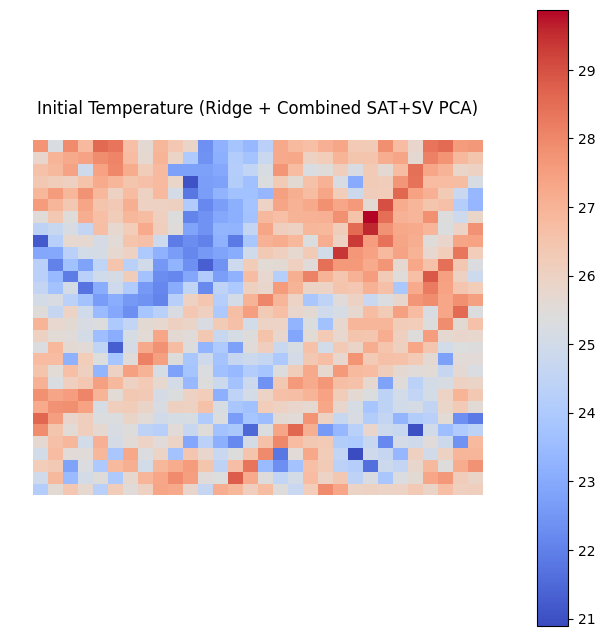

In [18]:
# ── Predict temperature on full grid ──────────────────────────────────────
X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features['predicted_temperature_ridge'] = ridge_predict(ridge_model, X_grid)

initial_temperature_map = gpd.GeoDataFrame(grid_features, geometry='geometry', crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_temperature_map.plot(column='predicted_temperature_ridge', cmap='coolwarm', legend=True, ax=ax)
ax.set_axis_off()
ax.set_title('Initial Temperature (Ridge + Combined SAT+SV PCA)')
plt.show()

In [19]:
# ── Sensor residuals ──────────────────────────────────────────────────────
sensor_model_df = sensor_cell_df[['sensor_name', target_col] + predictor_cols].dropna().copy()
sensor_model_df['ridge_pred_at_sensor'] = ridge_predict(
    ridge_model, sensor_model_df[predictor_cols].to_numpy(dtype=float)
)
sensor_model_df['residual'] = sensor_model_df[target_col] - sensor_model_df['ridge_pred_at_sensor']

sensors_proj = gdf_sensors.to_crs(initial_temperature_map.crs).copy()
sensors_proj['x'] = sensors_proj.geometry.x
sensors_proj['y'] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[['sensor_name', 'x', 'y']], on='sensor_name', how='left'
)
sensor_residuals_df

,sensor_name,temperature,combined_pc1,combined_pc2,ridge_pred_at_sensor,residual,x,y
0,Boston Carter Field,26.214514,0.712977,-0.027513,26.295959,-0.081445,234252.312622,898834.637669
1,Boston Gainsborough Parking Garage,28.377312,1.755323,0.312738,27.527551,0.849760,234191.453996,898960.969606
2,Boston Robinson Hall,28.198644,-0.756310,0.320724,25.147521,3.051123,234073.213353,898826.532851
3,Boston West Village B,22.676928,-1.075911,0.058034,24.657488,-1.980560,233591.199929,898653.278770
4,Boston World Series Way,24.120776,0.166943,0.229392,25.959654,-1.838878,233795.319059,898775.220621


Residual variogram model:
{'model': 'gaussian', 'nugget': 0.0, 'sill': 5.978029334179355, 'range': 198.4449346201937, 'score_mse': 11.644593056600682, 'lag_centers': [128.53819628807997, 214.23032714679997, 299.92245800551996, 471.30671972295994, 642.6909814403999], 'experimental_semivariance': [0.43357201560522574, 2.446509892617354, 11.956058668358708, 5.939196980910911, 2.904336278839383], 'fitted_semivariance': [2.04841867902829, 4.114126509088882, 5.369146286987503, 5.956803452948797, 5.977862860696772]}


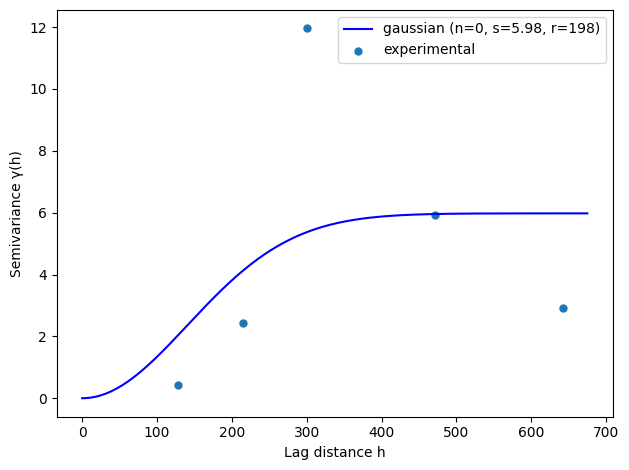

In [20]:
# ── Fit variogram ─────────────────────────────────────────────────────────
res_points = list(zip(sensor_residuals_df['x'].tolist(), sensor_residuals_df['y'].tolist()))
res_values = sensor_residuals_df['residual'].tolist()

residual_variogram_model = fit_variogram_model(points=res_points, values=res_values)
print('Residual variogram model:')
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

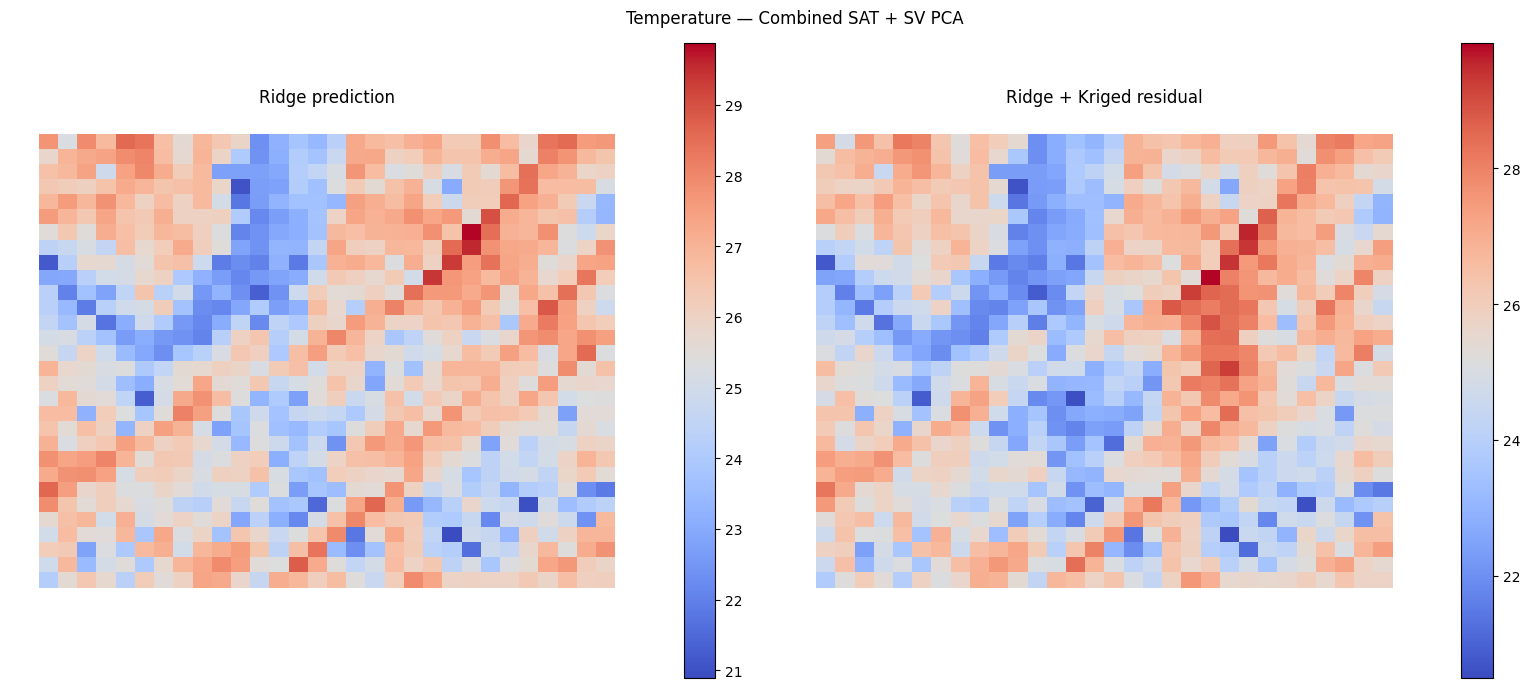

Saved → /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_combined/temperature_combined_kriging_grid.geojson
Temperature range: 20.50 – 29.84 °C


In [21]:
# ── Krige residuals → final temperature map ───────────────────────────────
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_temperature_map.geometry]
estimated_residuals = ordinary_kriging_predict(
    points=res_points, values=res_values,
    fit=residual_variogram_model, query_points=query_points,
)

final_temperature_map = initial_temperature_map.copy()
final_temperature_map['estimated_residual']  = estimated_residuals
final_temperature_map['final_temperature']   = (
    final_temperature_map['predicted_temperature_ridge'] + final_temperature_map['estimated_residual']
)

OUT_DIR = DATA_DIR / 'kriging_combined'
OUT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
initial_temperature_map.plot(column='predicted_temperature_ridge', cmap='coolwarm', legend=True, ax=axes[0])
axes[0].set_axis_off(); axes[0].set_title('Ridge prediction')
final_temperature_map.plot(column='final_temperature', cmap='coolwarm', legend=True, ax=axes[1])
axes[1].set_axis_off(); axes[1].set_title('Ridge + Kriged residual')
plt.suptitle('Temperature — Combined SAT + SV PCA')
plt.tight_layout()
plt.savefig(OUT_DIR / 'temperature_combined_map.png', dpi=300, bbox_inches='tight')
plt.show()

OUTPUT_PATH = OUT_DIR / 'temperature_combined_kriging_grid.geojson'
final_temperature_map.to_file(OUTPUT_PATH, driver='GeoJSON')
print(f'Saved → {OUTPUT_PATH}')
print(f'Temperature range: {final_temperature_map["final_temperature"].min():.2f} – {final_temperature_map["final_temperature"].max():.2f} °C')